<center><h1>Zhan_Jenna_HW5</h1></center>
<br>
<br>

Name:Jenna Zhan 
<br>
Github Username:jenna-zhan 
<br>
USC ID: 2477604908

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.tree import _tree
from sklearn.impute import SimpleImputer
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
column_names1 = [
    "Temperature",
    "Nausea",
    "Lumbar Pain",
    "Urine Pushing",
    "Micturition Pains",
    "Burning of Urethra",
    "Bladder Inflammation",
    "Nephritis"
]

diag = pd.read_csv(
    "../data/diagnosis.data",
    sep = "\t",
    header = None,
    names = column_names1,
    encoding = "utf-16",
    decimal = ","
)

display(diag.head())
display(diag.shape)
display(diag.dtypes)
display(diag.isnull().sum())

,Temperature,Nausea,Lumbar Pain,Urine Pushing,Micturition Pains,Burning of Urethra,Bladder Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


(120, 8)

Temperature             float64
Nausea                      str
Lumbar Pain                 str
Urine Pushing               str
Micturition Pains           str
Burning of Urethra          str
Bladder Inflammation        str
Nephritis                   str
dtype: object

Temperature             0
Nausea                  0
Lumbar Pain             0
Urine Pushing           0
Micturition Pains       0
Burning of Urethra      0
Bladder Inflammation    0
Nephritis               0
dtype: int64

### (b) Build a decision tree

In [3]:
bi_columns = column_names1[1:]

diag[bi_columns] = diag[bi_columns].apply(
    lambda column: column.map({"no": 0, "yes": 1})
)

diag.head()

,Temperature,Nausea,Lumbar Pain,Urine Pushing,Micturition Pains,Burning of Urethra,Bladder Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [4]:
X = diag.iloc[:, :6].copy()

y = (
    diag["Bladder Inflammation"].astype(str)
    + "_"
    + diag["Nephritis"].astype(str)
)


print(y.value_counts())

1_0    40
0_1    31
0_0    30
1_1    19
Name: count, dtype: int64


In [5]:
dt1 = DecisionTreeClassifier(
    criterion = "entropy",
    random_state = 552
)

dt1.fit(X, y)

print("training accuracy:", dt1.score(X, y))
print("tree depth:", dt1.get_depth())
print("number of leaves:", dt1.get_n_leaves())

training accuracy: 1.0
tree depth: 4
number of leaves: 6


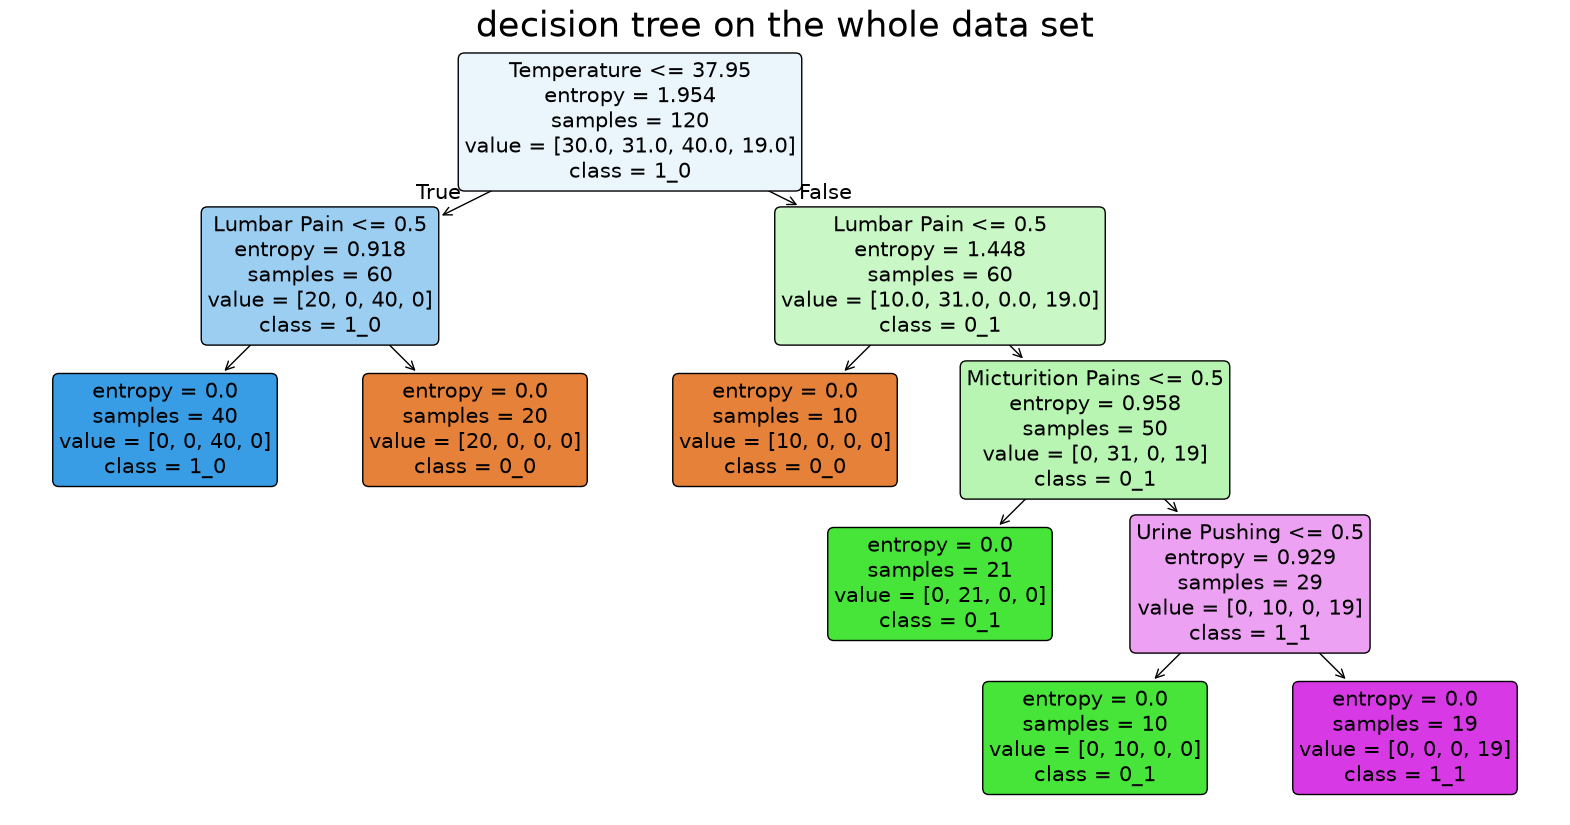

In [6]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt1,
    feature_names = X.columns,
    class_names = dt1.classes_,
    filled = True,
    rounded = True,
     fontsize = 15
)

plt.title("decision tree on the whole data set",fontsize=25)
plt.show()

### (c) Convert the decision rules

In [7]:
def tree_to_pseudo(tree_model, feature_names):
   
    tree_ = tree_model.tree_
    
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]

    def recurse(node, depth=0):
        indent = "    " * depth

        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]

            print(f"{indent}IF {name} <= {threshold:.2f}:")
            recurse(tree_.children_left[node], depth + 1)

            print(f"{indent}ELSE:  # {name} > {threshold:.2f}")
            recurse(tree_.children_right[node], depth + 1)

        else:
            class_index = np.argmax(tree_.value[node][0])
            predicted_class = tree_model.classes_[class_index]

            print(f"{indent}THEN class = {predicted_class}")

    recurse(0)

tree_to_pseudo(dt1, list(X.columns))

IF Temperature <= 37.95:
    IF Lumbar Pain <= 0.50:
        THEN class = 1_0
    ELSE:  # Lumbar Pain > 0.50
        THEN class = 0_0
ELSE:  # Temperature > 37.95
    IF Lumbar Pain <= 0.50:
        THEN class = 0_0
    ELSE:  # Lumbar Pain > 0.50
        IF Micturition Pains <= 0.50:
            THEN class = 0_1
        ELSE:  # Micturition Pains > 0.50
            IF Urine Pushing <= 0.50:
                THEN class = 0_1
            ELSE:  # Urine Pushing > 0.50
                THEN class = 1_1


### (d) Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

In [8]:
pruning_path = dt1.cost_complexity_pruning_path(X, y)
d_alphas = pruning_path.ccp_alphas

d_alphas

array([0.        , 0.19959209, 0.32501121, 0.45914792, 0.77042604])

In [9]:
pruned_trees = []

for alpha in d_alphas:
    model = DecisionTreeClassifier(
        criterion = "entropy",
        random_state = 552,
        ccp_alpha = alpha
    )
    
    model.fit(X, y)
    pruned_trees.append(model)

pruning_results = pd.DataFrame({
    "ccp_alpha": d_alphas,
    "accuracy": [model.score(X, y) for model in pruned_trees],
    "depth": [model.get_depth() for model in pruned_trees],
    "leaves": [model.get_n_leaves() for model in pruned_trees]
})

pruning_results

,ccp_alpha,accuracy,depth,leaves
0,0.000000,1.000000,4,6
1,0.199592,0.841667,2,4
2,0.325011,0.758333,2,3
3,0.459148,0.591667,1,2
4,0.770426,0.333333,0,1


I selected alpha = 0.199592 because it reduced the tree depth from 4 to 2 and the number of leaf nodes from 6 to 4, while retaining an accuracy of approximately 84.17%.

In [10]:
dt1_pruned = DecisionTreeClassifier(
    criterion = "entropy",
    random_state = 552,
    ccp_alpha = d_alphas[1]
)

dt1_pruned.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",552
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",np.float64(0.1995920879638124)
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relati

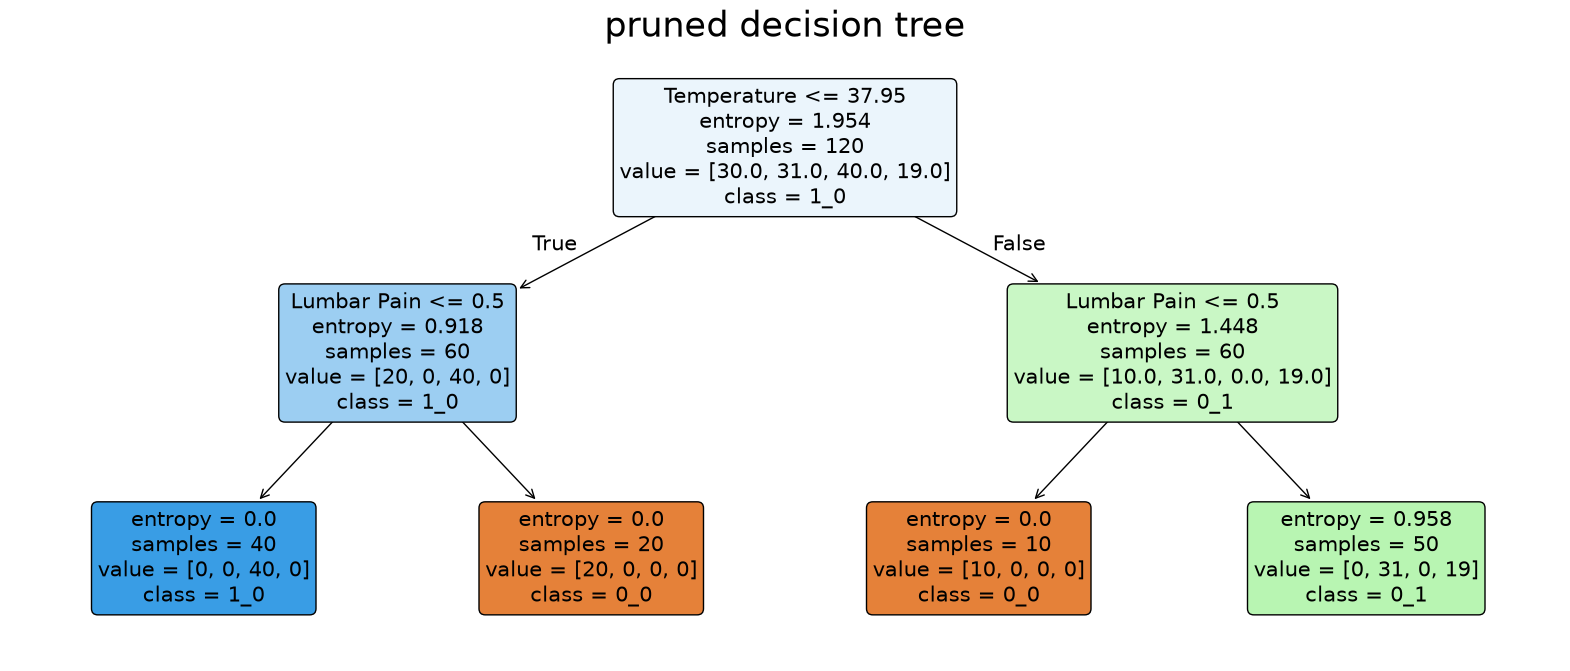

In [11]:
plt.figure(figsize=(20, 8))

plot_tree(
    dt1_pruned,
    feature_names = X.columns,
    class_names = dt1_pruned.classes_,
    filled = True,
    rounded = True,
    fontsize = 15
)

plt.title(
    "pruned decision tree",
    fontsize = 25
)

plt.show()

In [12]:
tree_to_pseudo(dt1_pruned, list(X.columns))

IF Temperature <= 37.95:
    IF Lumbar Pain <= 0.50:
        THEN class = 1_0
    ELSE:  # Lumbar Pain > 0.50
        THEN class = 0_0
ELSE:  # Temperature > 37.95
    IF Lumbar Pain <= 0.50:
        THEN class = 0_0
    ELSE:  # Lumbar Pain > 0.50
        THEN class = 0_1


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [13]:
attri_names = []

with open("../data/communities.names", "r") as file:
    for line in file:
        if line.startswith("@attribute"):
            attri_names.append(line.split()[1])

len(attri_names)

128

In [14]:
crime = pd.read_csv(
    "../data/communities.data",
    header = None,
    names = attri_names,
    na_values = "?"
)

display(crime.head())
crime.shape

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


(1994, 128)

In [15]:
train_data = crime.iloc[:1495].copy()
test_data = crime.iloc[1495:].copy()

print(train_data.shape)
print(test_data.shape)

(1495, 128)
(499, 128)


### (b) Missing values

In [16]:
non_pred = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

target = "ViolentCrimesPerPop"

In [17]:
X_train = train_data.drop(
    columns = non_pred + [target]
)

y_train = train_data[target]

X_test = test_data.drop(
    columns = non_pred + [target]
)

y_test = test_data[target]

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1495, 122)
(1495,)
(499, 122)
(499,)


In [18]:
imputer = SimpleImputer(strategy = "median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns = X_train.columns,
    index = X_train.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns = X_test.columns,
    index = X_test.index
)

print(X_train_imp.isnull().sum().sum())
print(X_test_imp.isnull().sum().sum())

print(X_train_imp.shape)
print(X_test_imp.shape)

X_train_imp.head()

0
0
(1495, 122)
(499, 122)


,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.29,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.28,0.02,0.12,0.45,0.07,0.03,0.76,0.5,0.00,0.15
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.28,0.01,0.21,0.02,0.07,0.03,0.76,0.5,0.00,0.15
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.28,0.02,0.39,0.28,0.07,0.03,0.76,0.5,0.00,0.15
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.28,0.04,0.09,0.02,0.07,0.03,0.76,0.5,0.00,0.15


Missing values were imputed using the median of each feature calculated
from the training set.

### (c) Plot a correlation matrix

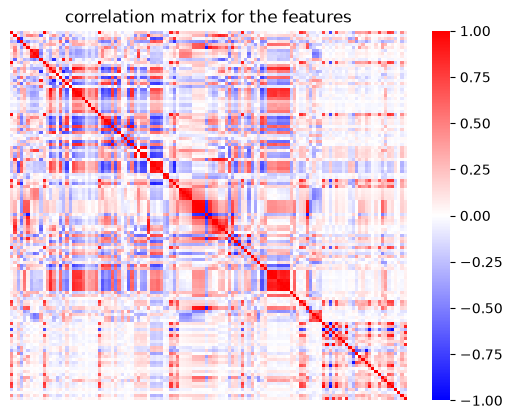

In [19]:
corr_matrix = X_train_imp.corr()

sns.heatmap(
    corr_matrix,
    cmap = "bwr",
    center = 0,
    vmin = -1,
    vmax = 1,
    xticklabels = False,
    yticklabels = False
)

plt.title("correlation matrix for the features")

plt.show()

### (d) Calculate the Coefficient of Variation CV

In [20]:
mean_24 = X_train_imp.mean()
std_24 = X_train_imp.std()

cv = std_24 / mean_24.replace(0, np.nan)

cv_results = pd.DataFrame({
    "sample_mean": mean_24,
    "standard_deviation": std_24,
    "CV": cv
}).sort_values(
    by = "CV",
    ascending = False
)

cv_results

,sample_mean,standard_deviation,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


### (e) Scatter plots and box plots for highest CV features

In [21]:
features_n = int(np.sqrt(128))
features_n

11

In [22]:
features_h = cv_results.head(features_n).index.tolist()

features_h

['PctPolicAsian',
 'NumStreet',
 'NumInShelters',
 'NumIlleg',
 'NumImmig',
 'LemasPctOfficDrugUn',
 'NumUnderPov',
 'LemasSwornFT',
 'population',
 'numbUrban',
 'HousVacant']

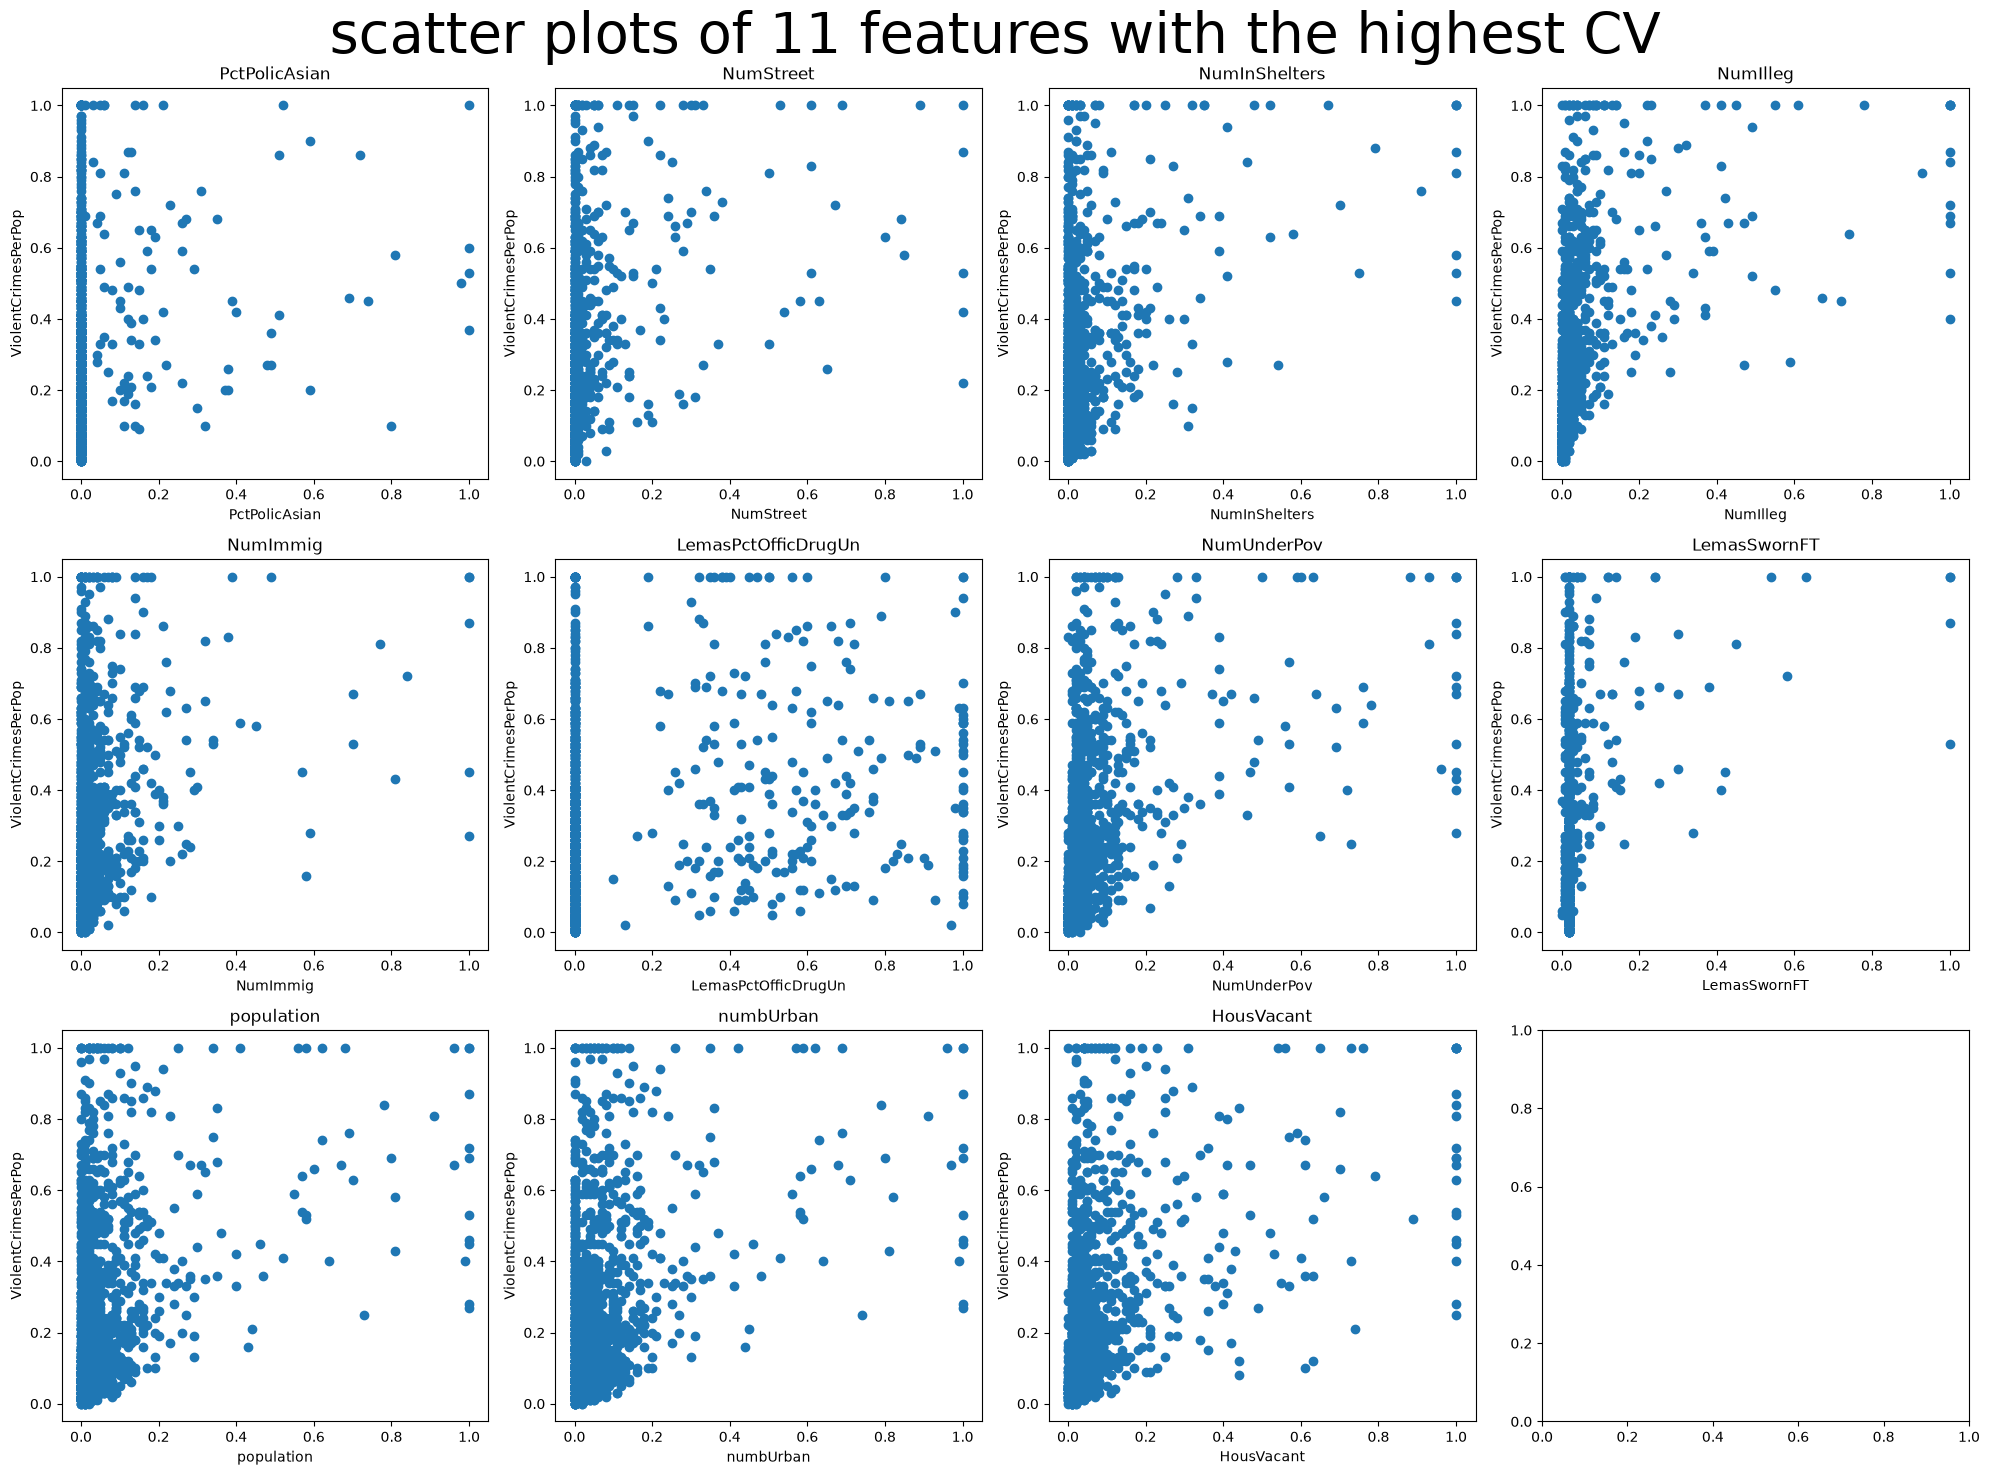

In [23]:
fig, axes = plt.subplots(
    3,
    4,
    figsize = (20, 15)
)

axes = axes.flatten()

for i, feature in enumerate(features_h):
    axes[i].scatter(
        X_train_imp[feature],
        y_train
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

plt.suptitle(
    "scatter plots of 11 features with the highest CV",
    fontsize = 40
)

plt.tight_layout()
plt.show()

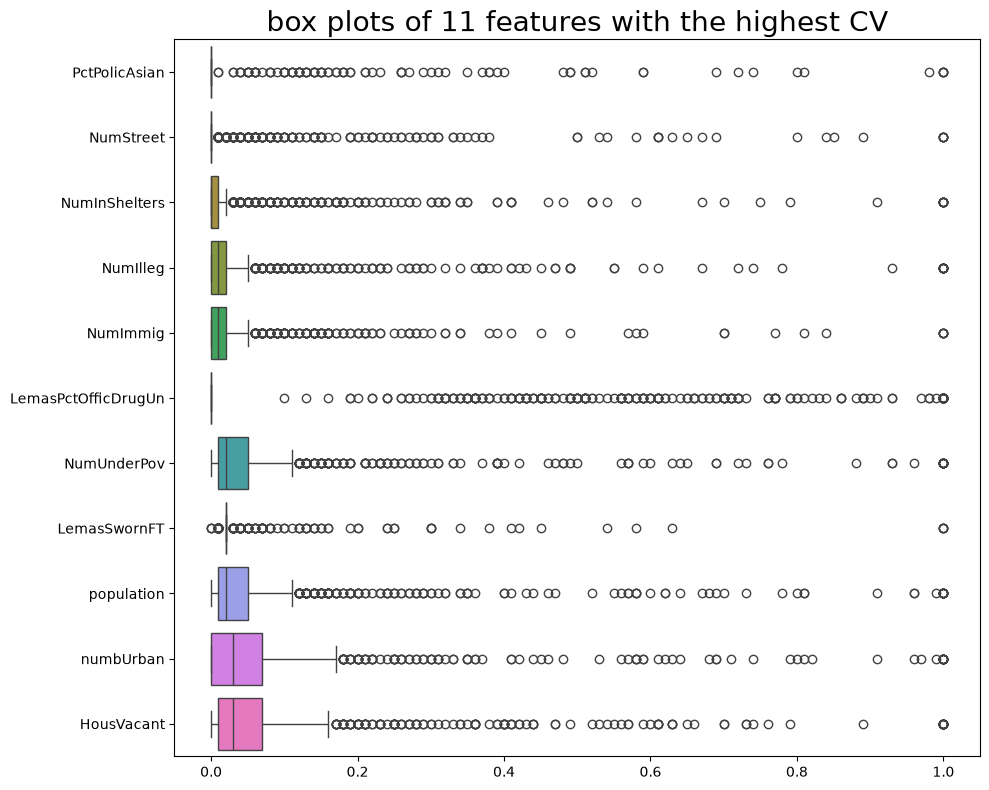

In [24]:
fig, axes = plt.subplots(
   figsize=(10, 8)
)

sns.boxplot(
    data = X_train_imp[features_h],
    orient = "h"
)

plt.title(
    "box plots of 11 features with the highest CV",
    fontsize = 20
)

plt.tight_layout()
plt.show()

Most feature values are concentrated near zero, indicating clearly right-skewed distributions. Many of the scatter plots do not show a clear linear trend. Although some larger feature values are associated with higher crime rates, the data points are widely dispersed. Therefore, the statistical significance of these features cannot be determined solely from the scatter plots.

### (f) Fit a linear model

In [25]:
li_model = LinearRegression()

li_model.fit(
    X_train_imp,
    y_train
)

y_test_pred = li_model.predict(X_test_imp)

li_test_mse = mean_squared_error(
    y_test,
    y_test_pred
)

print("the test error of linear model:", li_test_mse)

the test error of linear model: 0.01796621542606732


### (g) Fit a ridge regression model

In [26]:
r_alphas = np.logspace(-4, 4, 100)

r_model = RidgeCV(
    alphas = r_alphas,
    cv = 10,
    scoring = "neg_mean_squared_error"
)

r_model.fit(
    X_train_imp,
    y_train
)

print("best lambda:", r_model.alpha_)

best lambda: 2.310129700083163


In [27]:
r_test_pred = r_model.predict(X_test_imp)

r_test_mse = mean_squared_error(
    y_test,
    r_test_pred
)

print("the test error of ridge model:", r_test_mse)

the test error of ridge model: 0.01751624930256486


### (h) Fit a LASSO model

In [28]:
la_model = LassoCV(
    cv = 10,
    max_iter = 100000,
    random_state = 552
)

la_model.fit(
    X_train_imp,
    y_train
)

print("best lambda:", la_model.alpha_)

best lambda: 0.00010831930127505147


In [29]:
la_test_pred = la_model.predict(X_test_imp)

la_test_mse = mean_squared_error(
    y_test,
    la_test_pred
)

print("the test error of LASSO model:", la_test_mse)

the test error of LASSO model: 0.017646453683287242


In [30]:
selected_features = X_train_imp.columns[
    la_model.coef_ != 0
].tolist()

print(len(selected_features))

print("the variables selected by the model:", selected_features)

73
the variables selected by the model: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', '

In [31]:
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train_imp)
X_test_std = scaler.transform(X_test_imp)

la_std_model = LassoCV(
    cv = 10,
    max_iter = 100000,
    random_state = 552
)

la_std_model.fit(
    X_train_std,
    y_train
)

print("best lambda:", la_std_model.alpha_)

best lambda: 0.0006636910154760816


In [32]:
la_std_test_pred = la_std_model.predict(X_test_std)

la_std_test_mse = mean_squared_error(
    y_test,
    la_std_test_pred
)

print("the test error of Standardized LASSO model:", la_std_test_mse)

the test error of Standardized LASSO model: 0.017712332415203844


In [33]:
selected_features_std = X_train_imp.columns[
    la_std_model.coef_ != 0
].tolist()

print(len(selected_features_std))

print("the variables selected by the model:", selected_features_std)

75
the variables selected by the model: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85'

The unstandardized LASSO model selected an optimal lambda of approximately 0.000108, achieved a test MSE of approximately 0.01765, and selected 73 features. In comparison, the standardized LASSO model selected an optimal lambda of approximately 0.000664, achieved a test MSE of approximately 0.01771, and selected 75 features. Therefore, the unstandardized model performed slightly better, although the difference in test error was very small.

### (i) Fit a PCR model

In [34]:
pcr_ppl = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])

pcr_param = {
    "pca__n_components": np.arange(1, 123)
}

pcr_cv = GridSearchCV(
    estimator = pcr_ppl,
    param_grid = pcr_param,
    cv = 5,
    scoring = "neg_mean_squared_error"
)

pcr_cv.fit(
    X_train_imp,
    y_train
)

best_M = pcr_cv.best_params_["pca__n_components"]

print("the best number of principal components:", best_M)

the best number of principal components: 95


In [35]:
pcr_test_pred = pcr_cv.predict(X_test_imp)

pcr_test_mse = mean_squared_error(
    y_test,
    pcr_test_pred
)

print("the test error of PCR model:", pcr_test_mse)

the test error of PCR model: 0.01829634536770987


### (j) Fit a boosting tree

In [36]:
xgb_model = XGBRegressor(
    objective = "reg:squarederror",
    n_estimators = 300,
    learning_rate = 0.05,
    max_depth = 3,
    random_state = 552
)

xgb_param = {
    "reg_alpha": [
        0,
        0.0001,
        0.001,
        0.01,
        0.1,
        1,
        10
    ]
}

xgb_cv = GridSearchCV(
    estimator = xgb_model,
    param_grid = xgb_param,
    cv = 5,
    scoring = "neg_mean_squared_error"
)

xgb_cv.fit(
    X_train_imp,
    y_train
)

best_alpha = xgb_cv.best_params_["reg_alpha"]

print("best alpha:", best_alpha)

best alpha: 0.01


In [37]:
xgb_test_pred = xgb_cv.predict(X_test_imp)

xgb_test_mse = mean_squared_error(
    y_test,
    xgb_test_pred
)

print("the test error of XGBoost model:", xgb_test_mse)

the test error of XGBoost model: 0.0160720872413724


The XGBoost model has the lowest test error, so it performs the best.